In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dtypes = {
    "step": "int16", "type": "category", "amount": "float32",
    "nameOrig": "string", "oldbalanceOrg": "float32", "newbalanceOrig": "float32",
    "nameDest": "string", "oldbalanceDest": "float32", "newbalanceDest": "float32",
    "isFraud": "int8", "isFlaggedFraud": "int8",
}

df = pd.read_csv("../data/raw/PS_20174392719_1491204439457_log.csv", dtype=dtypes)
print(df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

(6362620, 11)
Memory: 0.39 GB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.0,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.280029,C1666544295,21249.0,19384.720703,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.000000,C1305486145,181.0,0.000000,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.000000,C840083671,181.0,0.000000,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.139648,C2048537720,41554.0,29885.859375,M1230701703,0.0,0.0,0,0


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int16   
 1   type            category
 2   amount          float32 
 3   nameOrig        string  
 4   oldbalanceOrg   float32 
 5   newbalanceOrig  float32 
 6   nameDest        string  
 7   oldbalanceDest  float32 
 8   newbalanceDest  float32 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float32(5), int16(1), int8(2), string(2)
memory usage: 376.0 MB


,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.000000,239.000000,3.350000e+02,743.0
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.570312,74871.937500,2.087215e+05,92445520.0
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.000000,14208.000000,1.073152e+05,59585040.0
newbalanceOrig,6362620.0,8.551136e+05,2.924048e+06,0.0,0.000000,0.000000,1.442584e+05,49585040.0
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.000000,132705.664062,9.430367e+05,356015904.0
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.000000,214661.445312,1.111909e+06,356179264.0
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.000000,0.000000,0.000000e+00,1.0
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.000000,0.000000,0.000000e+00,1.0


In [4]:
print(df["isFraud"].value_counts())
print(f"\nFraud rate: {df['isFraud'].mean():.4%}")

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud rate: 0.1291%


In [5]:
pd.crosstab(df["type"], df["isFraud"], margins=True)

isFraud,0,1,All
type,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2233384,4116,2237500
DEBIT,41432,0,41432
PAYMENT,2151495,0,2151495
TRANSFER,528812,4097,532909
All,6354407,8213,6362620


In [6]:
df_tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
print(df_tc.shape)
print(f"Fraud rate in TRANSFER/CASH_OUT: {df_tc['isFraud'].mean():.4%}")

(2770409, 11)
Fraud rate in TRANSFER/CASH_OUT: 0.2965%


In [7]:
# After a transaction, sender's balance should drop by the amount,
# and receiver's balance should rise by the amount
df_tc["errorOrig"] = df_tc["oldbalanceOrg"] - df_tc["amount"] - df_tc["newbalanceOrig"]
df_tc["errorDest"] = df_tc["oldbalanceDest"] + df_tc["amount"] - df_tc["newbalanceDest"]

df_tc.groupby("isFraud")[["errorOrig", "errorDest"]].apply(lambda g: (g.abs() > 0.01).mean())

,errorOrig,errorDest
isFraud,,
0,0.912034,0.279976
1,0.014246,0.593815


In [8]:
df_tc["drains_account"] = (df_tc["amount"] == df_tc["oldbalanceOrg"]) & (df_tc["newbalanceOrig"] == 0)
pd.crosstab(df_tc["drains_account"], df_tc["isFraud"], normalize="columns")

isFraud,0,1
drains_account,,
False,1.0,0.023012
True,0.0,0.976988


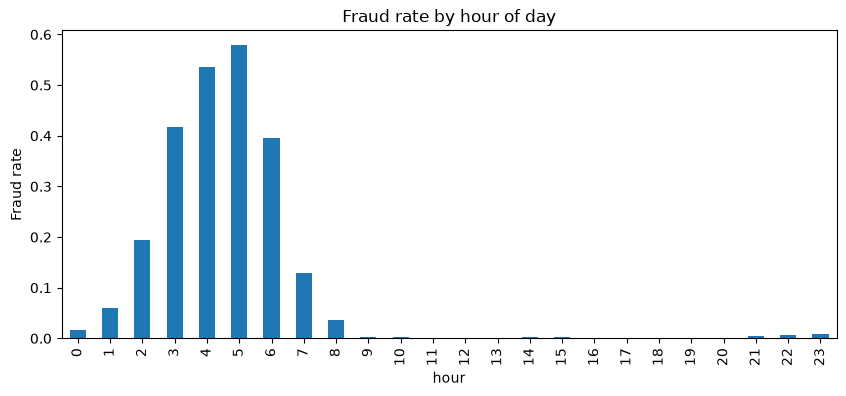

In [9]:
df_tc["hour"] = df_tc["step"] % 24
fraud_rate_by_hour = df_tc.groupby("hour")["isFraud"].mean()
fraud_rate_by_hour.plot(kind="bar", figsize=(10, 4), title="Fraud rate by hour of day")
plt.ylabel("Fraud rate")
plt.show()

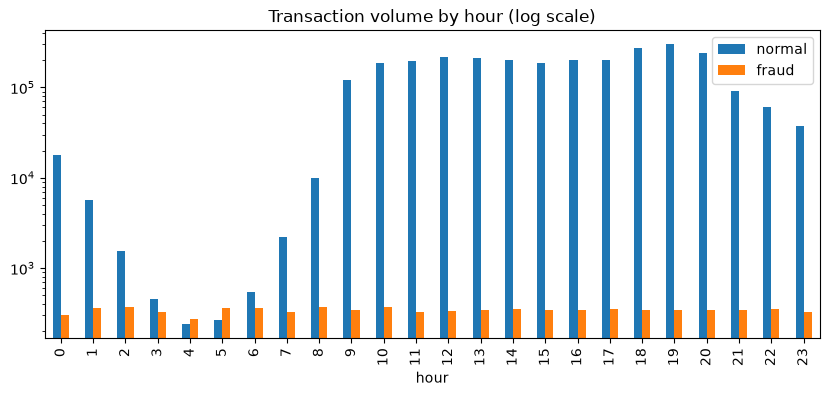

In [10]:
hourly = df_tc.groupby("hour")["isFraud"].agg(total="count", fraud="sum")
hourly["normal"] = hourly["total"] - hourly["fraud"]
hourly[["normal", "fraud"]].plot(kind="bar", figsize=(10, 4), logy=True,
                                  title="Transaction volume by hour (log scale)")
plt.show()

## Key findings

**1. Fraud is extremely rare (0.129%).**
8,213 fraudulent transactions out of 6,362,620. A model that predicts "not fraud" for everything would be 99.87% accurate and catch nothing, so accuracy is useless here. I will evaluate models with precision, recall, PR-AUC and a cost-based threshold instead.

**2. Fraud only occurs in TRANSFER and CASH_OUT.**
CASH_IN, DEBIT and PAYMENT contain zero fraud. The typical pattern is a two-step scheme: money is transferred from the victim's account to a mule account and then cashed out (4,097 vs 4,116 cases). I will restrict modelling to these two types, reducing the data from 6.3M to ~2.77M rows.

**3. The existing rule-based flag is ineffective.**
`isFlaggedFraud` flags only a handful of transactions against 8,213 real frauds. This is the business case for a model.

**4. Balance inconsistencies are a strong signal, but partly a simulation artifact.**
- Sender balance doesn't add up: 91% of normal transactions vs 1.4% of fraud.
- Receiver balance doesn't add up: 28% of normal vs 59% of fraud.

PaySim often fails to update balances for legitimate transactions, so this pattern is unlikely to carry over to real-world data. I will use it, but document it as a limitation.

**5. Fraud almost always empties the account.**
97.7% of fraudulent transactions drain the sender's full balance, compared with almost none of the normal transactions, which is consistent with account takeover behaviour.
 **Leakage risk:** `newbalanceOrig` is only known *after* a transaction is processed. A real-time model scores before approval, so I will only use pre-transaction information (e.g. `amount / oldbalanceOrg`) to capture this signal.

**6. Fraud rate peaks at night (2–7 a.m.).**
The fraud rate reaches ~58% at 5 a.m. This is mainly because legitimate volume drops sharply overnight while fraud continues. Fraudsters likely exploit hours when victims and operations teams are inactive. `hour` and an `is_night` flag will be useful features.

**7. `step` is one hour of simulated time.**
It ranges over 743 hours (~31 days). This lets me derive hour-of-day and split train/test by time (train on earlier weeks, test on the final week) to mimic real deployment.

### Implications for the next phases
- Filter to TRANSFER / CASH_OUT
- Use only pre-transaction features to avoid leakage
- Handle severe class imbalance
- Use a time-based train/test split

In [11]:
clean = pd.read_parquet("../data/clean/transactions.parquet")
print("Rows:            ", len(clean))
print("Unique senders:  ", clean["nameOrig"].nunique())
print("Unique receivers:", clean["nameDest"].nunique())
clean["nameDest"].value_counts().describe()

Rows:             2770409
Unique senders:   2768630
Unique receivers: 509565


count    509565.0
mean     5.436812
std      5.780369
min           1.0
25%           1.0
50%           3.0
75%           7.0
max          75.0
Name: count, dtype: double[pyarrow]